In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

Train samples: 60000, Test samples: 10000
Batches per epoch: 469
Batch image tensor shape: torch.Size([128, 1, 28, 28])


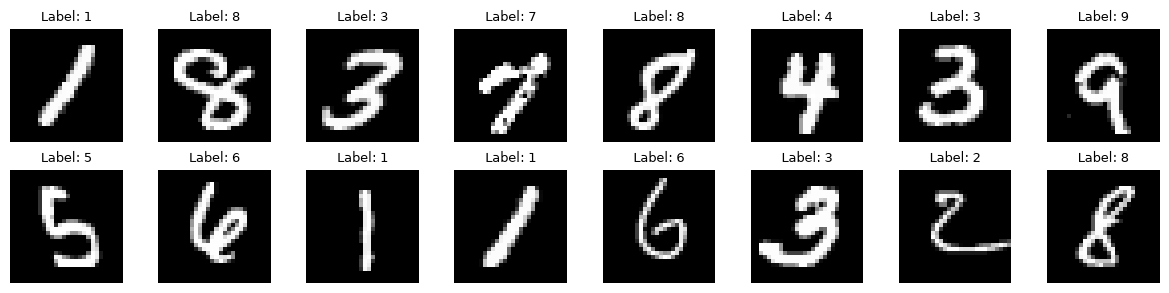

In [3]:


transform = transforms.Compose([
    transforms.ToTensor()
])

data_root = r"C:\Users\nevertheless\Desktop\oly\code\Generative-models\GAN\data"
train_dataset = datasets.MNIST(root=data_root, train=True, transform=transform, download = False)
test_dataset  = datasets.MNIST(root=data_root, train=False, transform=transform, download= False)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}")
print(f"Batches per epoch: {len(train_loader)}")

images, labels = next(iter(train_loader))

print(f"Batch image tensor shape: {images.shape}")  

fig, axes = plt.subplots(nrows=2, ncols=8, figsize=(12, 3))
for idx, ax in enumerate(axes.flat):
    ax.imshow(images[idx].squeeze(), cmap='gray')
    ax.set_title(f"Label: {labels[idx].item()}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()



In [54]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

device

'cuda'

In [55]:
T = 1000

betas = torch.linspace(1e-4 , 0.02 , T)
alpha = 1 - betas
alpha_bar = torch.cumprod(alpha, 0 ).to(device)

print("beta[0]:", betas[0].item())
print("alpha[0]:", alpha[0].item())
print("alpha_bar[0]:", alpha_bar[0].item())
print("alpha_bar[-1]:", alpha_bar[-1].item())


beta[0]: 9.999999747378752e-05
alpha[0]: 0.9998999834060669
alpha_bar[0]: 0.9998999834060669
alpha_bar[-1]: 4.0358307160204276e-05


In [56]:
def forward_diffusion(x0 , t):
    epsilon = torch.randn_like(x0)

    alpha_bar_t = alpha_bar[t].reshape(-1 , 1 , 1 , 1)
    mu = torch.sqrt(alpha_bar_t) * x0 
    sigma =  torch.sqrt(1-alpha_bar_t) * epsilon

    x_t = mu + sigma

    return x_t , epsilon


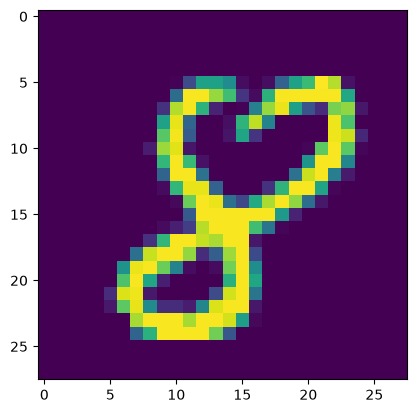

In [57]:
x0 = next(iter(train_loader))[0][0].squeeze(0)
plt.imshow(x0)

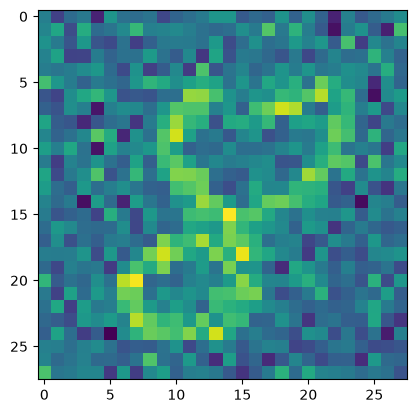

In [62]:
x_1 , _ = forward_diffusion(x0.to(device) , 100)
plt.imshow(x_1.reshape(28 , 28).cpu().numpy())

In [63]:
import torch.nn as nn

In [64]:
class NoisePredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv2d(1 ,
                32 , 
                kernel_size=3 , 
                padding=1 , 
                stride= 1),

            nn.ReLU(), 

            nn.Conv2d(32 ,
            64 , 
            kernel_size=3 , 
            padding=1 , 
            stride= 1),

            nn.ReLU(), 

            nn.Conv2d(64 ,
            1 , 
            kernel_size=3 , 
            padding=1 , 
            stride= 1)
      

        )

    def forward(self , x):

        return self.net(x)


In [65]:
model = NoisePredictor().to(device)

model(next(iter(train_loader))[0].to(device)).shape

torch.Size([128, 1, 28, 28])

In [66]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

In [67]:
next(iter(train_loader))[0].shape

torch.Size([128, 1, 28, 28])

In [78]:
import math

def sinusoidal_time_embedding(t, dim):
    half_dim = dim // 2

    frequencies = torch.exp(
        -math.log(10000) *
        torch.arange(half_dim, device=t.device).float() / half_dim
    )

    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

    embedding = torch.cat([
        torch.sin(angles),
        torch.cos(angles)
    ], dim=1)

    return embedding

In [75]:
def train_loop(dataloader, model, loss_fn, optimizer):
    model.train()
    for batch, (X, _) in enumerate(dataloader):
        X = X.to(device)
        t = torch.randint(0 , T , (X.shape[0],) , device=device)

        X_t , eps = forward_diffusion(X , t)

        eps_pred = model(X_t)

        loss = loss_fn(eps , eps_pred)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if batch % 100 == 0:
            loss, current = loss.item(), batch * batch_size + len(X)
            print(f"loss: {loss:>7f}")

for t in range(1):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loop(train_loader, model, loss_fn, optimizer)
    # test_loop(test_loader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 0.931581
loss: 0.135714
loss: 0.092222
loss: 0.062695
loss: 0.075253
Done!


t=100 | Noise prediction MSE: 0.177605
t=500 | Noise prediction MSE: 0.027282
t=900 | Noise prediction MSE: 0.009004


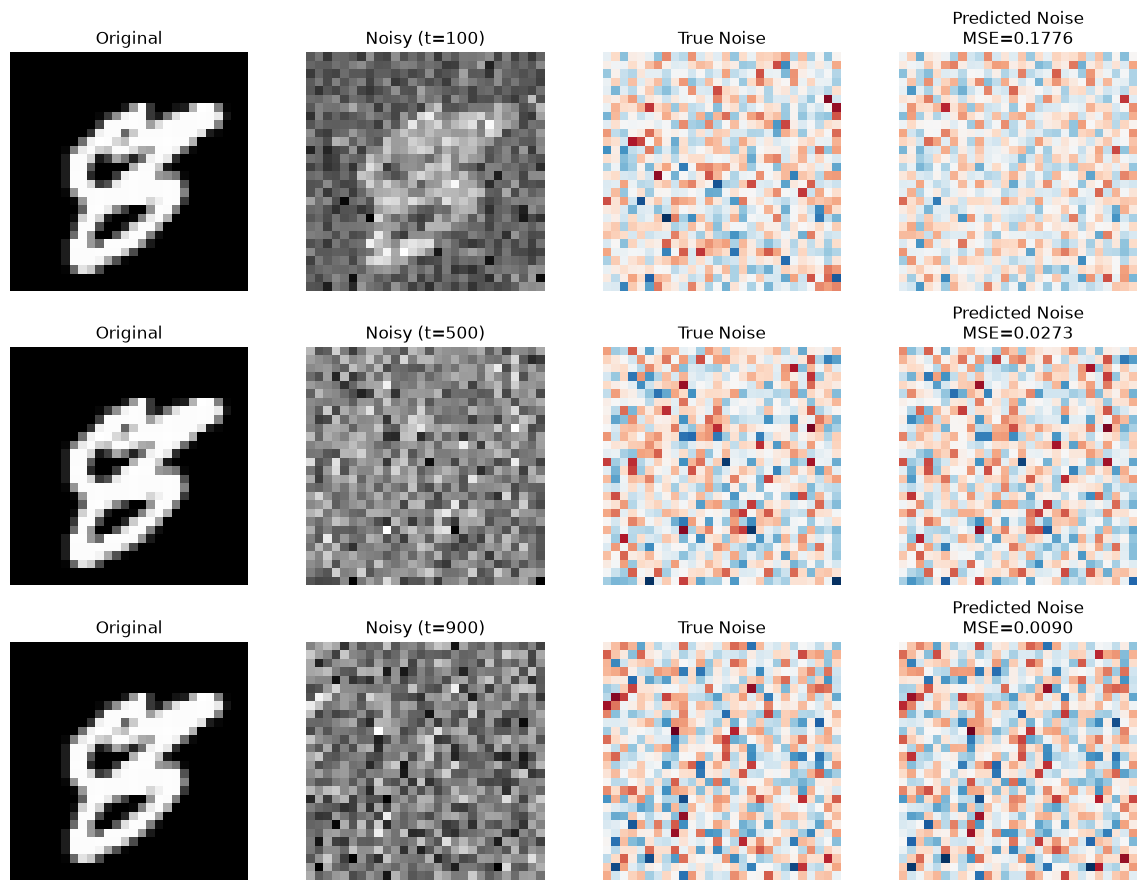

In [77]:
test_timesteps = [100, 500, 900]

images, _ = next(iter(train_loader))
x0 = images[:1].to(device)  

model.eval()

with torch.no_grad():
    fig, axes = plt.subplots(
        len(test_timesteps), 4, figsize=(12, 3 * len(test_timesteps))
    )

    for row, t_value in enumerate(test_timesteps):
        t = torch.tensor([t_value], dtype=torch.long, device=device)

        x_t, eps = forward_diffusion(x0, t)

        eps_pred = model(x_t)

        mse = torch.nn.functional.mse_loss(eps_pred, eps).item()

        original = x0[0, 0].cpu()
        noisy = x_t[0, 0].cpu()
        true_noise = eps[0, 0].cpu()
        predicted_noise = eps_pred[0, 0].cpu()

        axes[row, 0].imshow(original, cmap="gray")
        axes[row, 0].set_title("Original")

        axes[row, 1].imshow(noisy, cmap="gray")
        axes[row, 1].set_title(f"Noisy (t={t_value})")

        vmax = max(true_noise.abs().max().item(),
                   predicted_noise.abs().max().item())

        axes[row, 2].imshow(
            true_noise, cmap="RdBu_r", vmin=-vmax, vmax=vmax
        )
        axes[row, 2].set_title("True Noise")

        axes[row, 3].imshow(
            predicted_noise, cmap="RdBu_r", vmin=-vmax, vmax=vmax
        )
        axes[row, 3].set_title(f"Predicted Noise\nMSE={mse:.4f}")

        for ax in axes[row]:
            ax.axis("off")

        print(f"t={t_value:3d} | Noise prediction MSE: {mse:.6f}")

    plt.tight_layout()
    plt.show()
